# Dry Bean Classification — Model Training and Evaluation

**Assignment workflow:** dataset loading → preprocessing → train/test split → five classifiers → six evaluation metrics → confusion matrices → save trained pipelines and test data.

This notebook is designed to run in CATS Virtual Lab. It downloads the public UCI Dry Bean dataset when internet access is available. If the lab has no internet, download `Dry_Bean_Dataset.xlsx` from the [UCI dataset page](https://archive.ics.uci.edu/dataset/602/dry+bean) and upload it beside this notebook.

**Dataset requirement:** 13,611 rows, 16 numeric input features, and a 7-class target (`Class`). The notebook checks the dimensions before training.

**Important:** The test split is held out from model fitting. Preprocessing is included in each saved pipeline so the Streamlit app can load a model and evaluate uploaded test CSV files without retraining.


## 1. Install dependencies
Run this cell once if your environment does not already have these packages.

In [18]:
%pip install -q pandas numpy scikit-learn matplotlib seaborn openpyxl joblib ucimlrepo

Note: you may need to restart the kernel to use updated packages.


## 2. Imports and output folders

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix, classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

RANDOM_STATE = 42
OUTPUT_DIR = Path("dry_bean_classifier_output")
MODEL_DIR = OUTPUT_DIR / "model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder:", OUTPUT_DIR.resolve())

Output folder: /home/s2026aj05828/Downloads/dry_bean_classifier_output


## 3. Load the UCI Dry Bean dataset
The code first tries the `ucimlrepo` package. If the lab cannot access the internet, it falls back to a local Excel or CSV file.

In [4]:
df = None
load_errors = []

# Option A: download directly from UCI using its dataset ID.
try:
    from ucimlrepo import fetch_ucirepo
    dry_bean = fetch_ucirepo(id=602)
    features = dry_bean.data.features.copy()
    targets = dry_bean.data.targets.copy()
    if isinstance(targets, pd.DataFrame):
        target_col = "Class" if "Class" in targets.columns else targets.columns[0]
        targets = targets[target_col]
    df = features.copy()
    df["Class"] = pd.Series(targets).astype(str).values
    print("Loaded dataset directly from UCI.")
except Exception as exc:
    load_errors.append(f"UCI download failed: {exc}")

# Option B: use a file downloaded from UCI and placed next to the notebook.
if df is None:
    local_candidates = [
        Path("Dry_Bean_Dataset.xlsx"),
        Path("Dry_Bean_Dataset.xls"),
        Path("Dry_Bean_Dataset.csv"),
        Path("dry_bean.csv"),
    ]
    for file_path in local_candidates:
        if file_path.exists():
            if file_path.suffix.lower() in [".xlsx", ".xls"]:
                df = pd.read_excel(file_path)
            else:
                df = pd.read_csv(file_path)
            print(f"Loaded local file: {file_path}")
            break

if df is None:
    raise FileNotFoundError(
        "Could not download the dataset and no local file was found. "
        "Download Dry_Bean_Dataset.xlsx from https://archive.ics.uci.edu/dataset/602/dry+bean "
        "and upload it into the same folder as this notebook. Details: " + " | ".join(load_errors)
    )

df.columns = [str(c).strip() for c in df.columns]
# Standard UCI file uses 'Class'; handle a case variation if present.
target_matches = [c for c in df.columns if c.lower() == "class"]
if target_matches and target_matches[0] != "Class":
    df = df.rename(columns={target_matches[0]: "Class"})

display(df.head())
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Loaded dataset directly from UCI.


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


Dataset shape: (13611, 17)
Columns: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']


## 4. Validate and prepare the data
We require at least 500 rows and 12 input features. Missing numeric values are handled inside each pipeline. The target column is `Class`.

In [7]:
TARGET_COLUMN = "Class"

if TARGET_COLUMN not in df.columns:
    raise ValueError(
        f"Expected target column '{TARGET_COLUMN}'. Columns found: {df.columns.tolist()}. "
        "Check that you downloaded the official UCI Dry Bean dataset."
    )

# Drop rows where target is missing; input missing values are imputed within pipelines.
df = df.dropna(subset=[TARGET_COLUMN]).copy()
X = df.drop(columns=[TARGET_COLUMN]).copy()
y = df[TARGET_COLUMN].astype(str).copy()

# Ensure every feature is numeric.
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

# Remove any fully empty columns if present; official data should not have any.
empty_columns = [c for c in X.columns if X[c].isna().all()]
if empty_columns:
    X = X.drop(columns=empty_columns)
    print("Removed fully empty columns:", empty_columns)

print(f"Rows: {len(df):,}")
print(f"Input features: {X.shape[1]}")
print(f"Classes: {y.nunique()}")
print("Class counts:")
display(y.value_counts().rename_axis("Class").to_frame("Count"))

assert len(df) >= 500, "Dataset must have at least 500 instances."
assert X.shape[1] >= 12, "Dataset must have at least 12 input features."

feature_columns = X.columns.tolist()
class_names = sorted(y.unique().tolist())
print("\nFeature columns:", feature_columns)
print("\nDataset checks passed.")

Rows: 13,611
Input features: 16
Classes: 7
Class counts:


,Count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522



Feature columns: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']

Dataset checks passed.


## 5. Create training and test sets
We use a stratified 80:20 split so the class proportions are approximately preserved. The test set is not used to fit the models.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Train class distribution:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("Test class distribution:")
display(y_test.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

Training rows: 10888
Test rows: 2723
Train class distribution:


,proportion
Class,
BARBUNYA,0.097079
BOMBAY,0.038391
CALI,0.119765
DERMASON,0.260562
HOROZ,0.141624
SEKER,0.148880
SIRA,0.193699


Test class distribution:


,proportion
Class,
BARBUNYA,0.097319
BOMBAY,0.038193
CALI,0.119721
DERMASON,0.260375
HOROZ,0.141755
SEKER,0.149100
SIRA,0.193537


## 6. Define all five classification models
Scaling is used for Logistic Regression, KNN, and SVM. Decision Tree and Gaussian Naive Bayes do not require feature scaling, but all models use an imputer within the saved pipeline. `SVC(probability=True)` is used to calculate multiclass AUC.

In [13]:
models = {
    "Logistic Regression": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE, min_samples_leaf=2))
    ]),
    "KNN": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Gaussian Naive Bayes": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", GaussianNB())
    ]),
    "Support Vector Machine": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(probability=True, random_state=RANDOM_STATE))
    ])
}

print("Models to train:")
for name in models:
    print("-", name)

Models to train:
- Logistic Regression
- Decision Tree
- KNN
- Gaussian Naive Bayes
- Support Vector Machine


## 7. Train models and calculate the six required metrics
For multiclass AUC, this notebook uses **macro one-vs-rest ROC AUC**. Precision, recall, and F1 use macro averaging, which gives each class equal weight.

In [16]:
results = []
fitted_models = {}
predictions = {}
probabilities = {}

for model_name, pipeline in models.items():
    print(f"Training {model_name} ...")
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    # Probability estimates are needed for multiclass ROC AUC.
    y_proba = pipeline.predict_proba(X_test)
    fitted_models[model_name] = pipeline
    predictions[model_name] = y_pred
    probabilities[model_name] = y_proba

    # Use the class order learned by this model to align probability columns.
    model_classes = pipeline.named_steps["classifier"].classes_
    y_test_bin = label_binarize(y_test, classes=model_classes)
    auc = roc_auc_score(
        y_test_bin, y_proba,
        average="macro",
        multi_class="ovr"
    )

    results.append({
        "ML Model Name": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": auc,
        "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

metrics_df = pd.DataFrame(results).set_index("ML Model Name")
display(metrics_df.style.format("{:.4f}"))

# Save a plain CSV version for GitHub/README.
metrics_df.to_csv(OUTPUT_DIR / "metrics.csv")
print("Saved metrics to:", OUTPUT_DIR / "metrics.csv")

Training Logistic Regression ...
Training Decision Tree ...
Training KNN ...
Training Gaussian Naive Bayes ...
Training Support Vector Machine ...


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9207,0.9948,0.9349,0.9314,0.9329,0.9042
Decision Tree,0.8884,0.9531,0.9038,0.9041,0.9036,0.8652
KNN,0.9166,0.9833,0.9320,0.9271,0.9293,0.8992
Gaussian Naive Bayes,0.7639,0.9672,0.7744,0.7694,0.7677,0.7154
Support Vector Machine,0.9221,0.9949,0.9359,0.9330,0.9343,0.9059


Saved metrics to: dry_bean_classifier_output/metrics.csv


## 8. Compare model performance
The winner below is selected by the highest macro F1 score on the held-out test set. Review all metrics before drawing a conclusion; if scores are very close, mention that in your observations.

Overall winner by macro F1: Support Vector Machine

Metric ranking (highest first):


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Support Vector Machine,0.9221,0.9949,0.9359,0.9330,0.9343,0.9059
Logistic Regression,0.9207,0.9948,0.9349,0.9314,0.9329,0.9042
KNN,0.9166,0.9833,0.9320,0.9271,0.9293,0.8992
Decision Tree,0.8884,0.9531,0.9038,0.9041,0.9036,0.8652
Gaussian Naive Bayes,0.7639,0.9672,0.7744,0.7694,0.7677,0.7154


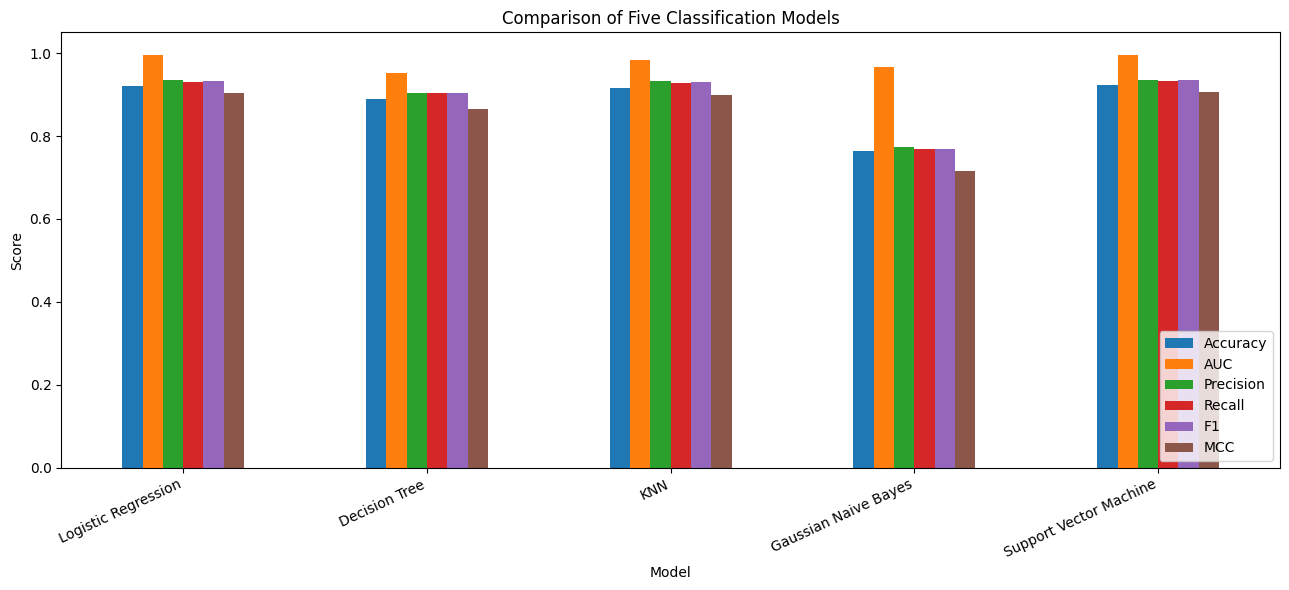

In [19]:
winner_name = metrics_df["F1"].idxmax()
print("Overall winner by macro F1:", winner_name)
print("\nMetric ranking (highest first):")
display(metrics_df.sort_values("F1", ascending=False).style.format("{:.4f}"))

metric_columns = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
ax = metrics_df[metric_columns].plot(kind="bar", figsize=(13, 6), ylim=(0, 1.05))
ax.set_title("Comparison of Five Classification Models")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 9. Confusion matrices and classification reports
These outputs help identify which bean classes each model confuses.


Logistic Regression
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.94      0.94       326
    DERMASON       0.92      0.91      0.92       709
       HOROZ       0.96      0.95      0.96       386
       SEKER       0.93      0.95      0.94       406
        SIRA       0.85      0.88      0.86       527

    accuracy                           0.92      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



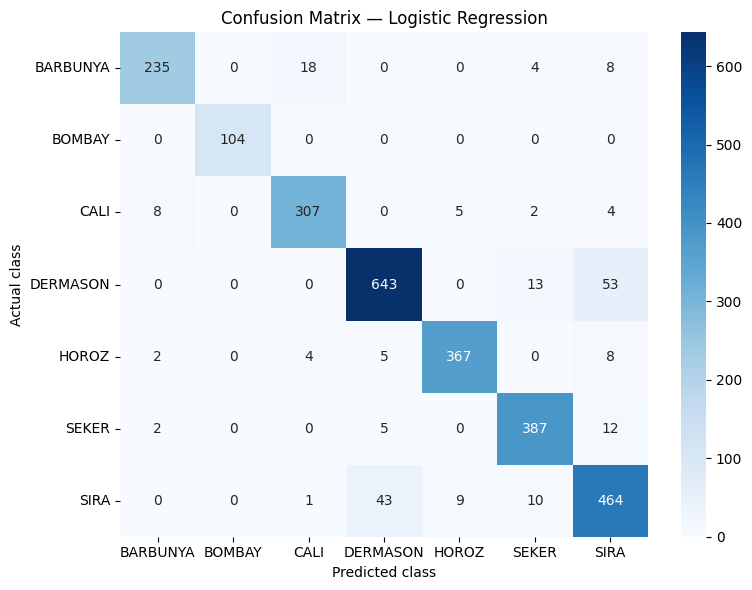


Decision Tree
              precision    recall  f1-score   support

    BARBUNYA       0.85      0.91      0.88       265
      BOMBAY       1.00      0.99      1.00       104
        CALI       0.92      0.89      0.90       326
    DERMASON       0.87      0.90      0.88       709
       HOROZ       0.94      0.93      0.94       386
       SEKER       0.92      0.93      0.92       406
        SIRA       0.84      0.78      0.81       527

    accuracy                           0.89      2723
   macro avg       0.90      0.90      0.90      2723
weighted avg       0.89      0.89      0.89      2723



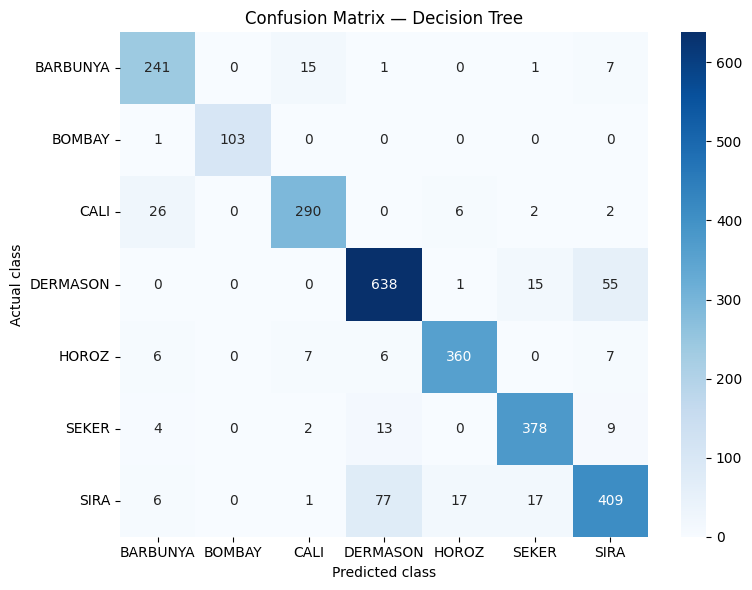


KNN
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.88      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.91      0.91      0.91       709
       HOROZ       0.95      0.95      0.95       386
       SEKER       0.95      0.94      0.95       406
        SIRA       0.84      0.87      0.86       527

    accuracy                           0.92      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



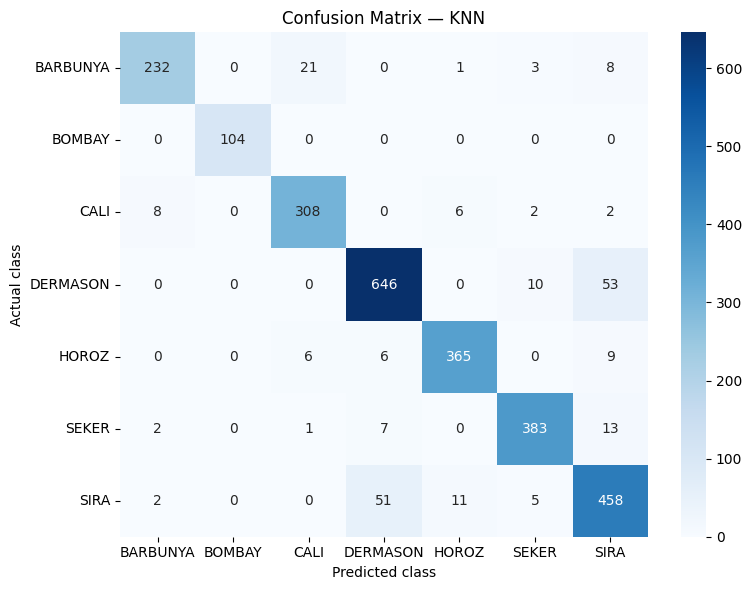


Gaussian Naive Bayes
              precision    recall  f1-score   support

    BARBUNYA       0.68      0.46      0.55       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.68      0.83      0.75       326
    DERMASON       0.87      0.83      0.85       709
       HOROZ       0.78      0.79      0.79       386
       SEKER       0.68      0.71      0.70       406
        SIRA       0.73      0.76      0.75       527

    accuracy                           0.76      2723
   macro avg       0.77      0.77      0.77      2723
weighted avg       0.77      0.76      0.76      2723



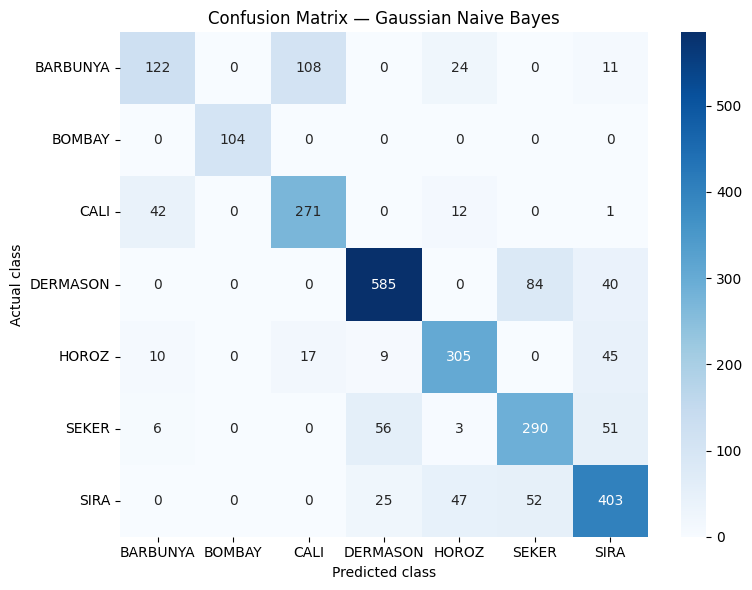


Support Vector Machine
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.95      0.94       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.96      0.96       386
       SEKER       0.94      0.95      0.94       406
        SIRA       0.86      0.87      0.87       527

    accuracy                           0.92      2723
   macro avg       0.94      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



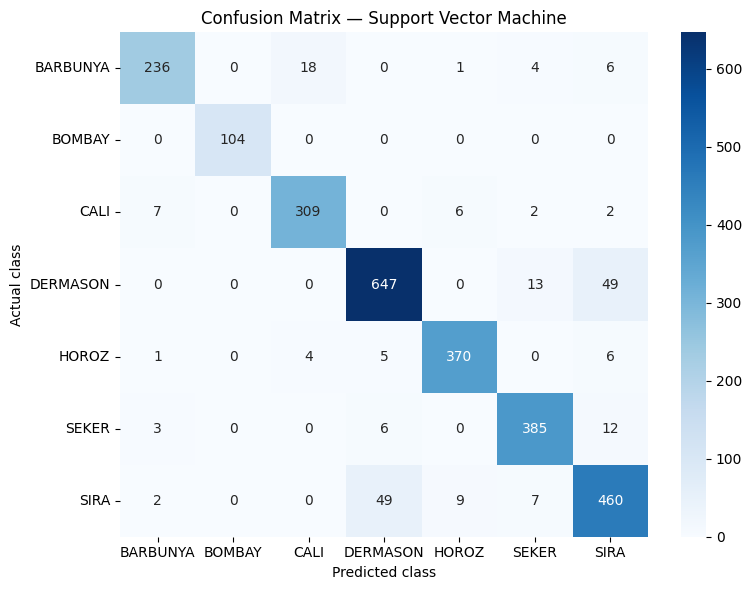

In [22]:
for model_name, y_pred in predictions.items():
    print("\n" + "=" * 80)
    print(model_name)
    print("=" * 80)
    print(classification_report(y_test, y_pred, labels=class_names, zero_division=0))

    cm = confusion_matrix(y_test, y_pred, labels=class_names)
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names, yticklabels=class_names
    )
    plt.title(f"Confusion Matrix — {model_name}")
    plt.xlabel("Predicted class")
    plt.ylabel("Actual class")
    plt.tight_layout()
    plt.show()

## 10. Save trained model pipelines
Each saved `.joblib` file contains preprocessing and the classifier. The Streamlit app can load these artifacts directly and will not train on uploaded test data.

In [24]:
model_filenames = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Gaussian Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

for model_name, pipeline in fitted_models.items():
    path = MODEL_DIR / model_filenames[model_name]
    joblib.dump(pipeline, path)
    print(f"Saved {model_name}: {path}")

print("\nModel directory:", MODEL_DIR.resolve())

Saved Logistic Regression: dry_bean_classifier_output/model/logistic_regression.joblib
Saved Decision Tree: dry_bean_classifier_output/model/decision_tree.joblib
Saved KNN: dry_bean_classifier_output/model/knn.joblib
Saved Gaussian Naive Bayes: dry_bean_classifier_output/model/naive_bayes.joblib
Saved Support Vector Machine: dry_bean_classifier_output/model/svm.joblib

Model directory: /home/s2026aj05828/Downloads/dry_bean_classifier_output/model


## 11. Export test data for the Streamlit app
The test CSV contains all required input features plus the true target column. Do not remove the target column, because the app must calculate evaluation metrics against the known labels.

In [27]:
test_data = X_test.copy()
test_data[TARGET_COLUMN] = y_test.values
test_csv_path = OUTPUT_DIR / "test_data.csv"
test_data.to_csv(test_csv_path, index=False)

# Also export a copy at the project root for easy upload to GitHub.
root_test_path = Path("test_data.csv")
test_data.to_csv(root_test_path, index=False)

print("Saved test CSV:", test_csv_path.resolve())
print("Saved root test CSV:", root_test_path.resolve())
print("Test CSV shape:", test_data.shape)
display(test_data.head())

Saved test CSV: /home/s2026aj05828/Downloads/dry_bean_classifier_output/test_data.csv
Saved root test CSV: /home/s2026aj05828/Downloads/test_data.csv
Test CSV shape: (2723, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
12803,36002,700.889,257.888986,178.268649,1.446631,0.722605,36368,214.100841,0.797386,0.989936,0.920954,0.830205,0.007163,0.002099,0.689241,0.997078,DERMASON
3713,183825,1594.423,582.225240,402.762055,1.445581,0.722124,185116,483.790512,0.797852,0.993026,0.908672,0.830934,0.003167,0.000931,0.690451,0.998102,BOMBAY
8974,45595,801.717,301.092828,193.505323,1.555992,0.766138,46054,240.942643,0.769926,0.990033,0.891425,0.800227,0.006604,0.001670,0.640363,0.996401,SIRA
1743,45084,763.811,261.138204,219.977872,1.187111,0.538882,45425,239.588672,0.773098,0.992493,0.971092,0.917478,0.005792,0.002532,0.841767,0.999271,SEKER
2303,61645,952.199,335.139136,235.843970,1.421021,0.710478,62499,280.158619,0.795522,0.986336,0.854382,0.835947,0.005437,0.001638,0.698808,0.993020,BARBUNYA


## 12. Generate observations for the README
Use these automatically generated observations as a starting point. Before submitting, read the actual scores and rewrite the observations in your own words.

In [30]:
observations = []
for model_name, row in metrics_df.iterrows():
    observations.append({
        "ML Model Name": model_name,
        "Observation about model performance": (
            f"Accuracy={row['Accuracy']:.3f}, macro AUC={row['AUC']:.3f}, "
            f"macro precision={row['Precision']:.3f}, macro recall={row['Recall']:.3f}, "
            f"macro F1={row['F1']:.3f}, MCC={row['MCC']:.3f}. "
            f"This model ranks {'first' if model_name == winner_name else 'below the top model'} "
            f"by macro F1 on this test split."
        )
    })

observations_df = pd.DataFrame(observations)
display(observations_df)
observations_df.to_csv(OUTPUT_DIR / "readme_observations.csv", index=False)

print("\nFinal generated artifacts:")
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file():
        print(f"{p} ({p.stat().st_size:,} bytes)")

,ML Model Name,Observation about model performance
0,Logistic Regression,"Accuracy=0.921, macro AUC=0.995, macro precisi..."
1,Decision Tree,"Accuracy=0.888, macro AUC=0.953, macro precisi..."
2,KNN,"Accuracy=0.917, macro AUC=0.983, macro precisi..."
3,Gaussian Naive Bayes,"Accuracy=0.764, macro AUC=0.967, macro precisi..."
4,Support Vector Machine,"Accuracy=0.922, macro AUC=0.995, macro precisi..."



Final generated artifacts:
dry_bean_classifier_output/metrics.csv (703 bytes)
dry_bean_classifier_output/model/decision_tree.joblib (142,731 bytes)
dry_bean_classifier_output/model/knn.joblib (1,483,678 bytes)
dry_bean_classifier_output/model/logistic_regression.joblib (3,873 bytes)
dry_bean_classifier_output/model/naive_bayes.joblib (3,961 bytes)
dry_bean_classifier_output/model/svm.joblib (533,085 bytes)
dry_bean_classifier_output/readme_observations.csv (988 bytes)
dry_bean_classifier_output/test_data.csv (494,482 bytes)


## 13. Final checks before moving files to GitHub

Check that these files exist:
- `dry_bean_classifier_output/model/*.joblib` — five saved models
- `dry_bean_classifier_output/metrics.csv` — evaluation results
- `dry_bean_classifier_output/test_data.csv` and root `test_data.csv` — held-out test data

Next, we will create `app.py`, `requirements.txt`, and `README.md`, then test the Streamlit app locally/in CATS before deploying.

**Reproducibility note:** Results can vary slightly with package versions. Keep the test split random state fixed at `42`, and report the values produced by your own run. Do not claim a model is the winner until the notebook has completed successfully.
